# Live LBM simulation

Run a small CPU Rayleigh–Bénard simulation and display its temperature field in a pyglet window with `lbm.render()`. The animation cell runs for a finite number of frames so it will finish normally. Interrupt it to stop early, then run the cleanup cell to close the window.

In [1]:
from controlRB import lbmd2q9

In [2]:
scale = 2
lbm = lbmd2q9(
    mode="cuda",
    NX=scale*128,
    NY=scale*64,
    Ra=1e6,
    verbose=False,
)

lbm.render(windowsize=1200, vmin=1.0, vmax=2.0)

Each frame advances the simulation by 40 lattice steps. Adjust `n_frames` for a longer or shorter run; temperature colors are fixed between 1 and 2 for consistent display.

Simulation time: [14400]
Step time: 1.1484224796295166
Render time: 1.091834545135498
Total time: 2.2402570247650146


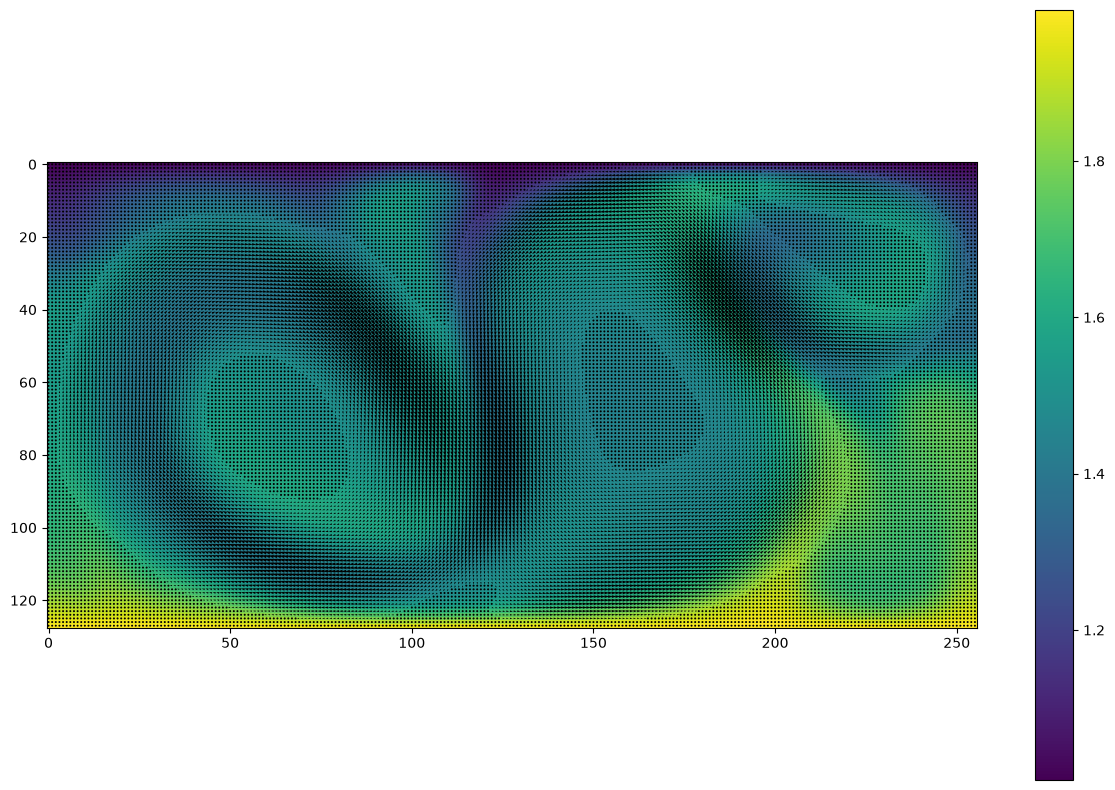

In [3]:
import time
n_frames = 180
steps_per_frame = int(40*lbm.NX/128)
step_time = render_time = 0.0
for _ in range(n_frames):
    t0 = time.time()
    lbm.allsteps(nsteps=steps_per_frame)
    step_time += time.time() - t0

    t0 = time.time()
    lbm.render(windowsize=800, vmin=1.0, vmax=2.0)
    render_time += time.time() - t0

print("Simulation time:", lbm.t.tolist())
print("Step time:", step_time)
print("Render time:", render_time)
print("Total time:", step_time + render_time)
lbm.flowtemplot()

Close the pyglet window and release the simulation resources when you are finished.

In [5]:
lbm.close()